(680,) (680,)
[1.0951189  1.31414268 1.53316646 1.75219024 1.97121402 2.1902378
 2.40926158 2.62828536 2.84730914 3.06633292] [-192.00776504 -190.87192649 -188.68101031 -185.87224633 -183.2377255
 -180.45702273 -177.79924367 -175.5316771  -173.63035333 -171.90771452]
0
3.591476174245006e-20 9.635035246509877e-15
power range: -192.00776503696716 -140.161466922865
freq: 1.0951188986232792 149.8122653316646


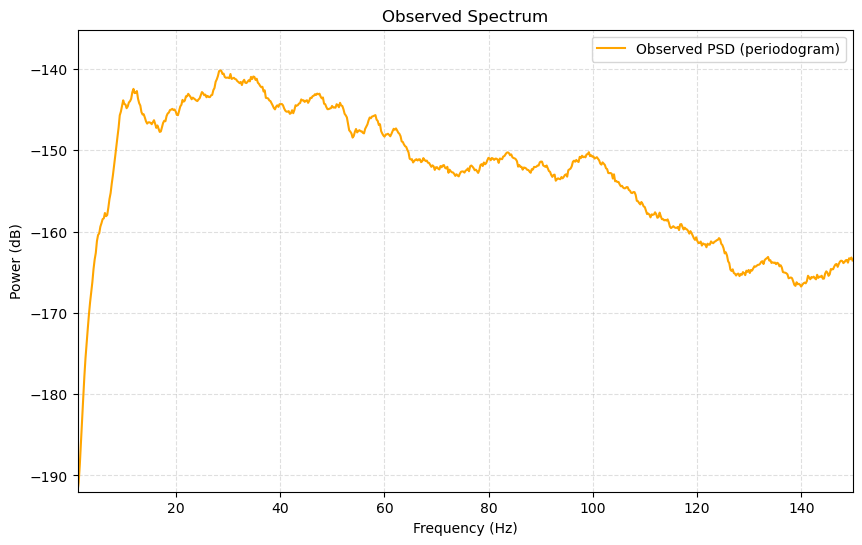

[147.84105131 148.06007509 148.27909887 148.49812265 148.71714643
 148.93617021 149.15519399 149.37421777 149.59324155 149.81226533]
350.0
dt: 0.002857142857142857 fs: 350.0


In [64]:
import obspy
from obspy import read
import numpy as np
import matplotlib.pyplot as plt
from signal_spectrum import signal_spectrum  # translated function
from obspy.clients.fdsn import Client
from scipy.signal import periodogram


s_emp = read("C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726123000.mseed")
#s_emp = read("C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726210000.mseed")

## multiply s_emp by 1e-6??

tr = s_emp[0]
dt = tr.stats.delta
fs = 1.0/dt

stas = [2301, 2302, 2303, 2304, 2305, 2306, 2307, 2308, 2309, 2310, 2311, 2312, 2313, 2314, 2315, 2316, 
        'G2301', 'G2302', 'G2303', 'G2304', 'G2305', 'G2306', 'G2307', 'G2308', 'G2309', 'G2310', 'G2311',
        'G2312', 'G2313', 'G2314', 'G2315', 'G2316'] 
stas = ['ZE.2416..GPZ'] # 3C station IDs
#stas = ['ZD.G2411.01.HDF'] # GEM station IDs
nowsta = stas[0]
network, station, location, channel = nowsta.split('.')
client = Client("IRISPH5", timeout=600)
inv = client.get_stations(network=network, station=station, location=location, channel=channel, level='response')

#pre_filt = (0.5, 0.8, 120.0, 160.0)
pre_filt=(0.5, 0.8, 150, 165) # need: upper corner < Nyquist, however 180 looks a bit more accurate on the high-freq end
#tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")  # PSD in (m²/s²)/Hz
                                                                    # velocity in m/s

p_emp = signal_spectrum(data=1e-6*tr.data,
                        dt=dt,
                        method="periodogram",
                        n=500,
                        res=800,
                        log=False)

# f, Pxx = periodogram(tr.data, fs=fs, window='hann', detrend='constant',
#                      scaling='density', return_onesided=True)


freq=p_emp['frequency']
power=p_emp['power'] # linear


psd_db = 10*np.log10(power)
#psd_db = 10 * np.log10(Pxx) - 120  # adjust for μm/s units
mask = (freq >= 1.0) & (freq <= 150.0)
freq=freq[mask]
psd_db=psd_db[mask]

print(freq.shape, psd_db.shape)
print(freq[:10], psd_db[:10])

print(np.isnan(psd_db).sum())
print(np.min(power), np.max(power))
print("power range:",np.min(psd_db), np.max(psd_db))
print("freq:",np.min(freq), np.max(freq))


plt.figure(figsize=(10, 6))
plt.plot(freq, psd_db, color="orange", label="Observed PSD (periodogram)")
plt.xlim(np.min(freq), np.max(freq))
plt.ylim(np.min(psd_db), np.max(psd_db)+5)
#plt.ylim(-160, -110)  # adjust based on your data
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.title("Observed Spectrum")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.show()


print(freq[-10:])
print(tr.stats.sampling_rate)


print("dt:", dt, "fs:", 1.0/dt)


(680,) (680,)
[1.0951189  1.31414268 1.53316646 1.75219024 1.97121402 2.1902378
 2.40926158 2.62828536 2.84730914 3.06633292] [-192.00776504 -190.87192649 -188.68101031 -185.87224633 -183.2377255
 -180.45702273 -177.79924367 -175.5316771  -173.63035333 -171.90771452]
0
3.591476174245006e-20 9.635035246509877e-15
power range: -192.00776503696716 -140.161466922865
freq: 1.0951188986232792 149.8122653316646


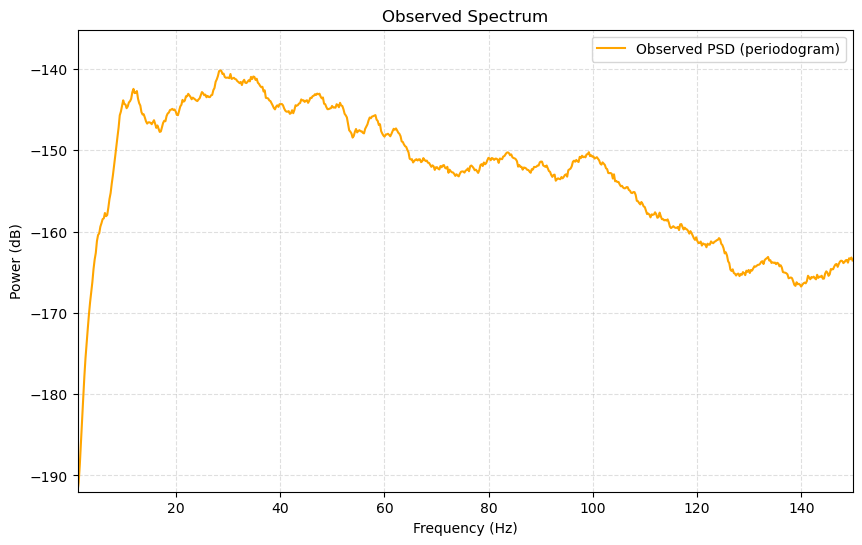

[147.84105131 148.06007509 148.27909887 148.49812265 148.71714643
 148.93617021 149.15519399 149.37421777 149.59324155 149.81226533]
350.0
dt: 0.002857142857142857 fs: 350.0


In [75]:
## copy of above with updated .py script
import obspy
from obspy import read
import numpy as np
import matplotlib.pyplot as plt
from signal_spectrum import signal_spectrum  # translated function
from obspy.clients.fdsn import Client
from scipy.signal import periodogram


s_emp = read("C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726123000.mseed")
#s_emp = read("C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726210000.mseed")

## multiply s_emp by 1e-6??

tr = s_emp[0]
dt = tr.stats.delta
fs = 1.0/dt

stas = [2301, 2302, 2303, 2304, 2305, 2306, 2307, 2308, 2309, 2310, 2311, 2312, 2313, 2314, 2315, 2316, 
        'G2301', 'G2302', 'G2303', 'G2304', 'G2305', 'G2306', 'G2307', 'G2308', 'G2309', 'G2310', 'G2311',
        'G2312', 'G2313', 'G2314', 'G2315', 'G2316'] 
stas = ['ZE.2416..GPZ'] # 3C station IDs
#stas = ['ZD.G2411.01.HDF'] # GEM station IDs
nowsta = stas[0]
network, station, location, channel = nowsta.split('.')
client = Client("IRISPH5", timeout=600)
inv = client.get_stations(network=network, station=station, location=location, channel=channel, level='response')

#pre_filt = (0.5, 0.8, 120.0, 160.0)
pre_filt=(0.5, 0.8, 150, 165) # need: upper corner < Nyquist, however 180 looks a bit more accurate on the high-freq end
#tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")  # PSD in (m²/s²)/Hz
                                                                    # velocity in m/s

p_emp = signal_spectrum(data=1e-6*tr.data,
                        dt=dt,
                        method="periodogram",
                        n=500,
                        res=800,
                        log=False)

# f, Pxx = periodogram(tr.data, fs=fs, window='hann', detrend='constant',
#                      scaling='density', return_onesided=True)


freq=p_emp['frequency']
power=p_emp['power'] # linear


psd_db = 10*np.log10(power)
#psd_db = 10 * np.log10(Pxx) - 120  # adjust for μm/s units
mask = (freq >= 1.0) & (freq <= 150.0)
freq=freq[mask]
psd_db=psd_db[mask]

print(freq.shape, psd_db.shape)
print(freq[:10], psd_db[:10])

print(np.isnan(psd_db).sum())
print(np.min(power), np.max(power))
print("power range:",np.min(psd_db), np.max(psd_db))
print("freq:",np.min(freq), np.max(freq))


plt.figure(figsize=(10, 6))
plt.plot(freq, psd_db, color="orange", label="Observed PSD (periodogram)")
plt.xlim(np.min(freq), np.max(freq))
plt.ylim(np.min(psd_db), np.max(psd_db)+5)
#plt.ylim(-160, -110)  # adjust based on your data
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.title("Observed Spectrum")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.show()


print(freq[-10:])
print(tr.stats.sampling_rate)


print("dt:", dt, "fs:", 1.0/dt)


dt=0.002857s, fs=350.0Hz, Nyquist=175.0Hz
Freq band: 0.0 175.0
dB range: -281.3915604852756 -136.00169588390497
Freq band: 1.0951188986232792 149.8122653316646
dB range in band: -164.91791797456267 -136.00169588390497
28.473091364205253 -136.00169588390497


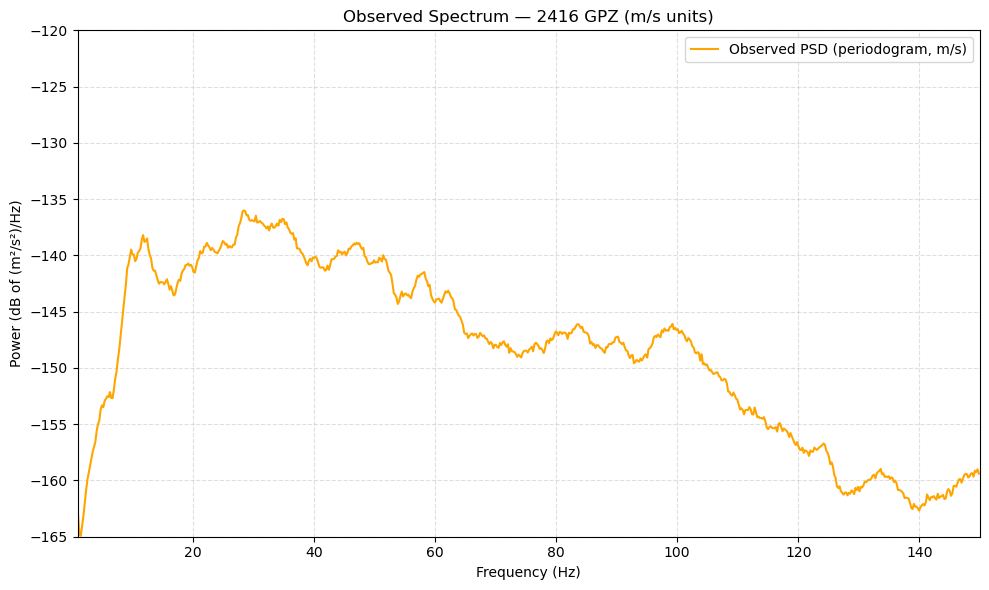

In [68]:
# --- Golden cell: observed PSD like the R HTML (m/s units, periodogram, smoothing, interpolation) ---

import numpy as np
import matplotlib.pyplot as plt
from obspy import read
from obspy.clients.fdsn import Client
from signal_spectrum import signal_spectrum  # Your translated function from R

# ---- 1) Load trace ----
mseed_path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\iris-data\seismic_data\NO2416\GPZ\ZE.2416..GPZ_20240726123000.mseed"
st = read(mseed_path)
tr = st[0].copy()

# ---- 2) Sampling/Inventory ----
dt = tr.stats.delta
fs = 1.0 / dt
print(f"dt={dt:.6f}s, fs={fs:.1f}Hz, Nyquist={fs/2:.1f}Hz")

# Station/channel metadata for response removal
nowsta = 'ZE.2416..GPZ'
network, station, location, channel = nowsta.split('.')
client = Client("IRISPH5", timeout=600)
inv = client.get_stations(network=network, station=station, location=location,
                          channel=channel, level='response')

# ---- 3) Remove instrument response -> velocity (m/s) ----
# Use upper corner < Nyquist (fs/2 ~ 175 Hz)
pre_filt = (0.5, 0.8, 150.0, 165.0)
tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")

# ---- 4) Spectrum using the R-translated function (periodogram) ----
# Match the R flow: periodogram estimator, n=500 smoothing, res=800 interpolation, linear frequency spacing
spec = signal_spectrum(
    data=tr.data,     # numeric array of signal values
    dt=dt,            # sampling period
    method="periodogram",
    n=500,            # running-mean smoothing window (samples)
    res=800,          # interpolation resolution
    log=False         # linear-frequency interpolation (like your R HTML)
)

freq = spec['frequency']
power = spec['power']        # linear PSD, units ~ (m^2/s^2)/Hz

# ---- 5) Safe dB conversion (NO unit shift) ----
eps = np.finfo(float).tiny
psd_db = 10 * np.log10(np.maximum(power, eps))  # dB of (m^2/s^2)/Hz

# ---- 6) Clip to 1–150 Hz ----
m = (freq >= 1.0) & (freq <= 150.0)
freq_plot = freq[m]
psd_plot = psd_db[m]


print("Freq band:", float(freq.min()), float(freq.max()))
print("dB range:", float(psd_db.min()), float(psd_db.max()))

print("Freq band:", float(freq_plot.min()), float(freq_plot.max()))
print("dB range in band:", float(psd_plot.min()), float(psd_plot.max()))


i = np.argmax(power)      # index of max PSD in the whole spectrum
print(freq[i], 10*np.log10(power[i]))


# ---- 7) Plot ----
plt.figure(figsize=(10, 6))
plt.plot(freq_plot, psd_plot, color="orange", label="Observed PSD (periodogram, m/s)")
plt.xlim(1, 150)
# Choose a y-range you want to inspect. R’s figure often used −160..−120 for these river spectra:
plt.ylim(-165, -120)  # widen if needed (-170..-120); adjust after you see the curve
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB of (m²/s²)/Hz)")
plt.title(f"Observed Spectrum — {station} {channel} (m/s units)")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from obspy import read
from obspy.clients.fdsn import Client
from signal_spectrum import signal_spectrum  # Your translated function from R

# ---- 1) Load trace ----
mseed_path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\iris-data\seismic_data\NO2416\GPZ\ZE.2416..GPZ_20240726123000.mseed"
st = read(mseed_path)
tr = st[0].copy()

# ---- 2) Sampling/Inventory ----
dt = tr.stats.delta
fs = 1.0 / dt
print(f"dt={dt:.6f}s, fs={fs:.1f}Hz, Nyquist={fs/2:.1f}Hz")

# Station/channel metadata for response removal
nowsta = 'ZE.2416..GPZ'
network, station, location, channel = nowsta.split('.')
client = Client("IRISPH5", timeout=600)
inv = client.get_stations(network=network, station=station, location=location,
                          channel=channel, level='response')

# ---- 3) Remove instrument response -> velocity (m/s) ----
# Use upper corner < Nyquist (fs/2 ~ 175 Hz)
pre_filt = (0.5, 0.8, 150.0, 165.0)
tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")

# ---- 4) Spectrum using the R-translated function (periodogram) ----
# Match the R flow: periodogram estimator, n=500 smoothing, res=800 interpolation, linear frequency spacing


spec = signal_spectrum(
    data=tr.data,     # numeric array of signal values
    dt=dt,            # sampling period
    method="periodogram",
    n=500,            # running-mean smoothing window (samples)
    res=800,          # interpolation resolution
    log=False         # linear-frequency interpolation (like your R HTML)
)

freq = spec['frequency']
power = spec['power']        # linear PSD, units ~ (m^2/s^2)/Hz

# ---- 5) Safe dB conversion (NO unit shift) ----
eps = np.finfo(float).tiny
psd_db = 10 * np.log10(np.maximum(power, eps))  # dB of (m^2/s^2)/Hz

# ---- 6) Clip to 1–150 Hz ----
m = (freq >= 1.0) & (freq <= 150.0)
freq_plot = freq[m]
psd_plot = psd_db[m]


print("Freq band:", float(freq.min()), float(freq.max()))
print("dB range:", float(psd_db.min()), float(psd_db.max()))

print("Freq band:", float(freq_plot.min()), float(freq_plot.max()))
print("dB range in band:", float(psd_plot.min()), float(psd_plot.max()))


i = np.argmax(power)      # index of max PSD in the whole spectrum
print(freq[i], 10*np.log10(power[i]))


# ---- 7) Plot ----
plt.figure(figsize=(10, 6))
plt.plot(freq_plot, psd_plot, color="orange", label="Observed PSD (periodogram, m/s)")
plt.xlim(1, 150)
# Choose a y-range you want to inspect. R’s figure often used −160..−120 for these river spectra:
plt.ylim(-165, -120)  # widen if needed (-170..-120); adjust after you see the curve
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB of (m²/s²)/Hz)")
plt.title(f"Observed Spectrum — {station} {channel} (m/s units)")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\zzawol\AppData\Local\miniforge3\envs\obspyenv\Lib\site-packages\obspy\core\util\base.py:26: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


SyntaxError: 'return' outside function (signal_spectrum.py, line 295)

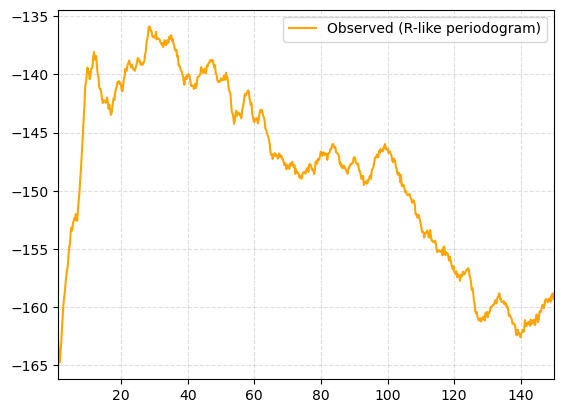

power range: -369.00601608132934 -135.8873616548418
freq: 0.0 175.0


In [74]:
import numpy as np
from scipy.signal import periodogram, windows
import matplotlib.pyplot as plt

def r_like_periodogram(x, fs, taper_alpha=0.1, n_smooth=500, res=800, log_spacing=False):
    # 1) Apply R-like taper: Tukey with alpha ≈ 0.1 (spec.pgram taper=0.1)
    w = windows.tukey(len(x), alpha=taper_alpha)
    ##w = windows.turkey(tr.data.size, alpha=0.1) ### added
    # periodogram accepts a window array directly
    f, Pxx = periodogram(x, fs=fs, window=w, detrend='constant', scaling='density', nfft=None)

    # 2) Running-mean smoothing in LINEAR domain (centered)
    if n_smooth and n_smooth > 1:
        k = int(n_smooth)
        kernel = np.ones(k, dtype=float) / float(k)
        Pxx = np.convolve(Pxx, kernel, mode='same')  # centered, like R runmean

    # 3) Interpolate to fixed resolution (avoid cubic overshoot)
    if res and res > 0:
        if log_spacing:
            # avoid f=0 in log spacing
            fmin_pos = f[1] if f[0] == 0 else max(f.min(), f[f > 0].min())
            f_target = np.exp(np.linspace(np.log(fmin_pos), np.log(f.max()), res))
        else:
            f_target = np.linspace(f.min(), f.max(), res)
        Pxx = np.interp(f_target, f, Pxx)  # linear interpolation
        f = f_target

    return f, Pxx

mseed_path = r"C:\Users\zzawol\OneDrive - DOI\Documents\MORA25\iris-data\seismic_data\NO2416\GPZ\ZE.2416..GPZ_20240726123000.mseed"
st = read(mseed_path)
tr = st[0].copy()

# ---- 2) Sampling/Inventory ----
dt = tr.stats.delta
#fs = 1.0 / dt
#print(f"dt={dt:.6f}s, fs={fs:.1f}Hz, Nyquist={fs/2:.1f}Hz")

# Station/channel metadata for response removal
nowsta = 'ZE.2416..GPZ'
network, station, location, channel = nowsta.split('.')
client = Client("IRISPH5", timeout=600)
inv = client.get_stations(network=network, station=station, location=location,
                          channel=channel, level='response')

# ---- 3) Remove instrument response -> velocity (m/s) ----
# Use upper corner < Nyquist (fs/2 ~ 175 Hz)
pre_filt = (0.5, 0.8, 150.0, 165.0)
tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")

# --- USE IT ON YOUR TRACE ---
x = tr.data.astype(float)

# If your R path multiplies by 1e-6 to get m/s, match that here:
# x = x * 1e-6  # uncomment if your Python data is still in µm/s

fs = 1.0 / dt
f, Pxx = r_like_periodogram(x, fs, taper_alpha=0.1, n_smooth=500, res=800, log_spacing=False)

# dB conversion (safe)
eps = np.finfo(float).tiny
psd_db = 10*np.log10(np.maximum(Pxx, eps))

# Clip to the band you compare (e.g., 1–150 Hz)
m = (f >= 1.0) & (f <= 150.0)
plt.plot(f[m], psd_db[m], color='orange', label='Observed (R-like periodogram)')
plt.xlim(1, 150)
#plt.ylim(-160, -110)
plt.grid(True, which='both', ls='--', alpha=0.4)
plt.legend()
plt.show()

print("power range:",np.min(psd_db), np.max(psd_db))
print("freq:",np.min(f), np.max(f))

#print(tr.data[:1000])

In [ ]:
import numpy as np
from scipy.signal import windows

# --- R-like call to your existing function ---
w = windows.tukey(tr.data.size, alpha=0.1)  # 10% taper like R spec.pgram
spec = signal_spectrum(
    data=tr.data,    # already velocity (m/s) after remove_response, per your note
    dt=dt,
    method="periodogram",
    n=500,           # centered running-mean on linear PSD (same as your R HTML)
    res=800,         # interpolate to 800 points for plotting
    log=False,       # linear frequency spacing (your R HTML top plot)
    # --- forward to scipy.signal.periodogram ---
    window=w,
    detrend='constant',
    scaling='density',
    nfft=tr.data.size
)

freq  = spec['frequency']
power = spec['power']                 # linear PSD: (m^2/s^2)/Hz

# dB conversion (safe)
eps    = 1e-300                       # use a reasonable floor to avoid -3,000 dB
psd_db = 10*np.log10(np.clip(power, eps, None))

# match band and axes to R figure
m = (freq >= 1) & (freq <= 150)
plt.plot(freq[m], psd_db[m], color='orange', label='Observed (R-like)')
plt.xlim(1, 150)
plt.ylim(-160, -110)                  # same y-limits as your R plots
plt.grid(True, which='both', ls='--', alpha=0.4)
plt.legend()
plt.show()

## sanity check
f, Pxx = spec['frequency'], spec['power']
m = (f >= 1) & (f <= 150)
print("Band dB min/max:", 
      10*np.log10(np.clip(Pxx[m], 1e-300, None)).min(),
      10*np.log10(np.clip(Pxx[m], 1e-300, None)).max())


dt=0.002857s, fs=350.0Hz, Nyquist=175.0Hz
power range: -220.05498933632794 -131.52367614810578
freq: 1.0 150.0


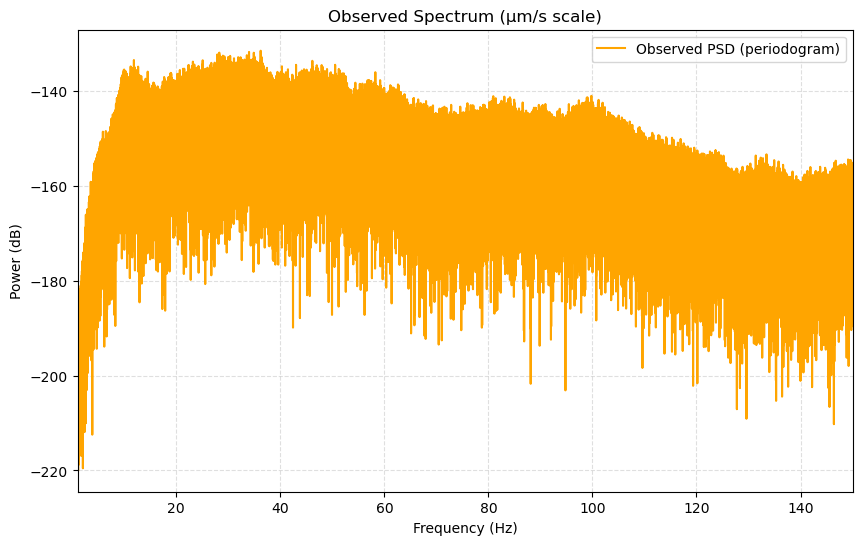

IndexError: boolean index did not match indexed array along dimension 0; dimension is 268201 but corresponding boolean dimension is 315001

In [58]:
from obspy import read
from scipy.signal import periodogram
import numpy as np
import matplotlib.pyplot as plt

# --- Load mSEED ---
st = read("C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726123000.mseed")
tr = st[0]

# --- Sampling info ---
dt = tr.stats.delta
fs = 1.0 / dt
print(f"dt={dt:.6f}s, fs={fs:.1f}Hz, Nyquist={fs/2:.1f}Hz")

# --- Compute PSD using periodogram ---
f, Pxx = periodogram(tr.data, fs=fs, window='hann', detrend='constant',
                     scaling='density', return_onesided=True)

# --- Convert to dB and adjust for μm/s units ---
psd_db = 10 * np.log10(Pxx) - 120  # subtract 120 dB to match R's μm/s scale

# --- Clip to 1–150 Hz ---
mask = (f >= 1.0) & (f <= 150.0)
f = f[mask]
psd_db = psd_db[mask]

print("power range:",np.min(psd_db), np.max(psd_db))
print("freq:",np.min(f), np.max(f))

# --- Plot ---
plt.figure(figsize=(10, 6))
plt.plot(f, psd_db, color='orange', label='Observed PSD (periodogram)')
plt.xlim(1, 150)
#plt.ylim(-160, -120)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.title("Observed Spectrum (μm/s scale)")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.show()

print("dB min/max in band:", float(psd_db[m].min()), float(psd_db[m].max()))

print("dB range:", psd_db.min(), psd_db.max())

dt=0.002857 s, fs=350.00 Hz, Nyquist=175.00 Hz
Freq range: 0.0 175.0


C:\Users\zzawol\AppData\Local\Temp\1\ipykernel_24136\3327213387.py:41: RuntimeWarning: divide by zero encountered in log10
  psd_db = 10.0 * np.log10(Pxx)


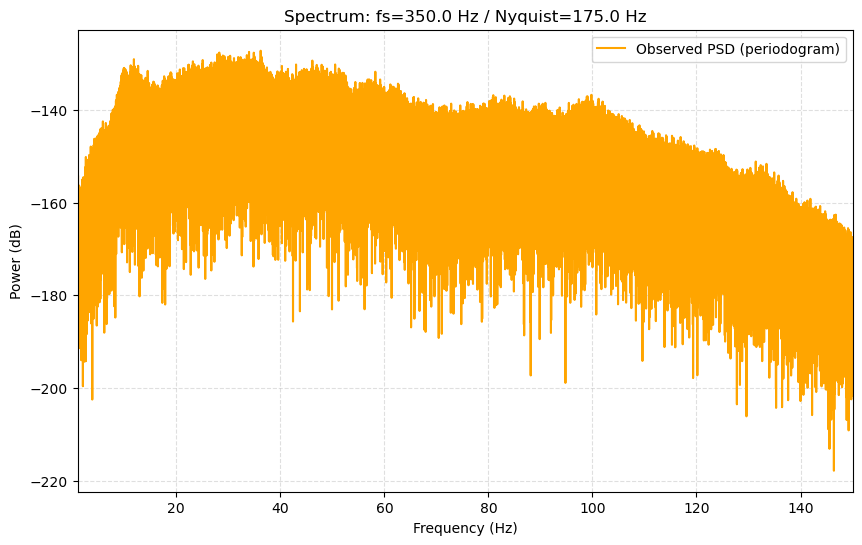

dB min/max in band: -217.842253950678 -127.26862078635097


In [36]:
import numpy as np
import matplotlib.pyplot as plt
from obspy import read

# --- Load data ---
st = read(r"C:/Users/zzawol/OneDrive - DOI/Documents/MORA25/iris-data/seismic_data/NO2416/GPZ/ZE.2416..GPZ_20240726123000.mseed")
tr = st[0].copy()

# --- Inspect sampling ---
dt = tr.stats.delta
fs = 1.0 / dt
print(f"dt={dt:.6f} s, fs={fs:.2f} Hz, Nyquist={fs/2:.2f} Hz")

# --- EITHER: remove response to m/s OR manually scale your counts ---
USE_REMOVE_RESPONSE = True  # set False to test the alternative path

if USE_REMOVE_RESPONSE:
    # Make sure your Inventory 'inv' is correct for this station/channel
    # pre_filt corners must be below Nyquist
    stas = ['ZE.2416..GPZ'] # 3C station IDs
    #stas = ['ZD.G2411.01.HDF'] # GEM station IDs
    nowsta = stas[0]
    network, station, location, channel = nowsta.split('.')
    client = Client("IRISPH5", timeout=600)
    inv = client.get_stations(network=network, station=station, location=location, channel=channel, level='response')
    pre_filt = (0.5, 0.8, 120.0, 160.0)
    tr.remove_response(inventory=inv, pre_filt=pre_filt, output="VEL")
    #print("NOTE: remove_response commented until you supply 'inv' for the channel.")
    # Do NOT multiply by 1e-6 if you output="VEL" (already m/s)
else:
    # If you do NOT have inventory, and you know counts ≈ μm/s, emulate R:
    tr.data = tr.data.astype(float) * 1e-6  # μm/s -> m/s
    print("Applied manual 1e-6 scaling (counts→m/s)")

# --- Periodogram with explicit params ---
from scipy.signal import periodogram
f, Pxx = periodogram(tr.data, fs=fs, window='hann', detrend='constant',
                     scaling='density', return_onesided=True)

print("Freq range:", f.min(), f.max())
psd_db = 10.0 * np.log10(Pxx)

# --- Clip band & plot ---
fmin, fmax = 1.0, min(150.0, fs/2.0)  # cap at 150 Hz or Nyquist, whichever is smaller
m = (f >= fmin) & (f <= fmax)

plt.figure(figsize=(10, 6))
plt.plot(f[m], psd_db[m], color='orange', label='Observed PSD (periodogram)')
plt.xlim(fmin, fmax)
#plt.ylim(-170, -110)  # adjust to your signal; try [-160, -120] next
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB)")
plt.title(f"Spectrum: fs={fs:.1f} Hz / Nyquist={fs/2:.1f} Hz")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.show()

print("dB min/max in band:", float(psd_db[m].min()), float(psd_db[m].max()))

UsageError: Cell magic `%%R` not found.
